In [1]:
import math


def biseccion(f, a, b, TOL, N0=100):
    """Devuelve (p, historia), con historia = [(a, b, p) por iteración]."""
    FA = f(a)
    if FA * f(b) >= 0:
        raise ValueError("f(a) y f(b) deben tener signos opuestos")
    historia = []
    i = 1
    while i <= N0:
        p = a + (b - a) / 2                                     # COMPLETE: punto medio estable
        FP = f(p)
        historia.append((a, b, p))                        # COMPLETE: (a, b, p)
        if FP == 0 or (b - a) / 2 < TOL:                          # COMPLETE: parada por TOL
            return p, historia    
        i = i + 1
        if FA * FP > 0:
            a = p                                     # COMPLETE: mover a
            FA = FP                                     # COMPLETE: mover a y FA
        else:
            b = p                                     # COMPLETE: mover b
    raise RuntimeError(f"fracasó después de {N0} iteraciones")

def f(x):
    m, k, g, s0 = 0.25, 0.1, 9.81, 300
    return s0 - m*g*x/k + m**2*g/k**2*(1 - math.exp(-k*x/m))

biseccion(f, 0, 30, 0.01)

(14.72900390625,
 [(0, 30, 15.0),
  (0, 15.0, 7.5),
  (7.5, 15.0, 11.25),
  (11.25, 15.0, 13.125),
  (13.125, 15.0, 14.0625),
  (14.0625, 15.0, 14.53125),
  (14.53125, 15.0, 14.765625),
  (14.53125, 14.765625, 14.6484375),
  (14.6484375, 14.765625, 14.70703125),
  (14.70703125, 14.765625, 14.736328125),
  (14.70703125, 14.736328125, 14.7216796875),
  (14.7216796875, 14.736328125, 14.72900390625)])

x* = 4.493414


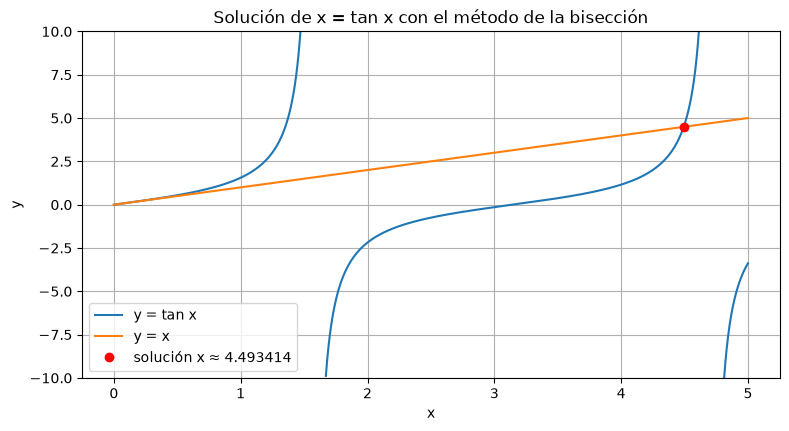

In [6]:
import numpy as np
import matplotlib.pyplot as plt

def f_tan(x):
    return x - np.tan(x)


def graficar_tan(x_star, archivo="grafica_tan.png"):
    """Dibuja y = x y y = tan x en [0, 5] y marca la solución x_star."""
    x = np.linspace(0, 5, 4000)
    y = np.tan(x)
    y[np.abs(y) > 10] = np.nan          # evita la línea vertical falsa en las asíntotas
    plt.figure(figsize=(9, 4.5))
    plt.plot(x, y, label="y = tan x")
    plt.plot(x, x, label="y = x")
    plt.plot(x_star, x_star, "ro", label=f"solución x ≈ {x_star:.6f}")
    plt.ylim(-10, 10)
    plt.xlabel("x")
    plt.ylabel("y")
    plt.title("Solución de x = tan x con el método de la bisección")
    plt.legend()
    plt.grid(True)
    plt.savefig(archivo, dpi=150)
    plt.show()


x_star, historia_tan = biseccion(f_tan, 4.2, 4.6, TOL=1e-5)
print(f"x* = {x_star:.6f}")
graficar_tan(x_star)